# Análisis del comportamiento meteorológico y variables climáticas (ENE -JUN 2012)

## Proyecto Final

## GRUPO 9


*   Oscar Luis Gallardo
*   Gabriel Ollier
*   Augusto Rosso




## Objetivos
Explorar y comprender la distribución de las variables meteorológicas (temperatura, humedad, presión, radiación), identificar patrones estacionales a lo largo del año, detectar y limpiar anomalías en las mediciones, y encontrar correlaciones clave entre los distintos fenómenos climáticos.

- reconocer la estructura y el significado de un dataset;
- diferenciar variables numéricas, categóricas, temporales e identificadores;
- detectar faltantes, duplicados, formatos inconsistentes y valores atípicos;
- justificar decisiones de limpieza según el contexto;
- transformar variables y crear nuevas características interpretables.


## Variable objetivo

> **La variable objetivo es la temperatura ambiental (`temp_c`), y el objetivo del proyecto es pronosticarla y estimarla con precisión analizando su comportamiento en función de factores meteorológicos clave, como la presión atmosférica, la radiación solar y la humedad.**

# Parte 1 — Carga y exploración inicial

## Conociendo nuestro dataset



## Preparación: cargar el dataset

In [ ]:
# impotamos la libreria y le asignamos el alias correspondiente.
import pandas as pd

df = pd.read_csv('/content/informacion-meteorologica-2012.csv')

In [ ]:
display(df.shape)#dimensiones del dataset

(29559, 11)

In [ ]:
df.head(10)#vista inicial

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
0,2012-01-01,00:00:00,1283,0.4,67.5,24.6,65,1010.8,0,0,0.0
1,2012-01-01,00:00:00,1284,2.7,135.0,24.8,60,1011.6,0,0,0.0
2,2012-01-01,00:00:00,1286,0.0,112.5,24.8,60,1012.6,0,0,0.0
3,2012-01-01,00:00:00,1291,0.0,180.0,24.6,59,1011.5,0,0,0.0
4,2012-01-01,00:00:00,1296,0.4,45.0,24.9,57,1010.4,0,0,0.0
5,2012-01-01,00:00:00,1305,0.4,90.0,25.1,61,1010.5,0,0,0.0
6,2012-01-01,00:00:00,1309,3.6,90.0,24.1,71,1011.7,0,0,0.0
7,2012-01-01,00:00:00,1310,2.7,90.0,24.7,60,1012.0,0,0,0.0
8,2012-01-01,00:00:00,1314,1.8,90.0,25.1,58,1010.7,0,0,0.0
9,2012-01-01,00:00:00,1318,0.4,67.5,1802.6,60,1011.9,0,0,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29559 entries, 0 to 29558
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fecha         29559 non-null  object 
 1   hora          29559 non-null  object 
 2   estacion      29559 non-null  int64  
 3   vv_m_s        29559 non-null  float64
 4   dv            29559 non-null  float64
 5   temp_c        29559 non-null  float64
 6   hr_porc       29559 non-null  int64  
 7   press_mbar    29559 non-null  float64
 8   pluv_mm       29559 non-null  int64  
 9   rad_sol_w_m2  29559 non-null  int64  
 10  uv_uvindex    29559 non-null  float64
dtypes: float64(5), int64(4), object(2)
memory usage: 2.5+ MB


In [ ]:
display(df.dtypes)

,0
fecha,object
hora,object
estacion,int64
vv_m_s,float64
dv,float64
temp_c,float64
hr_porc,int64
press_mbar,float64
pluv_mm,int64
rad_sol_w_m2,int64


In [ ]:
df.isnull().sum()

,0
fecha,0
hora,0
estacion,0
vv_m_s,0
dv,0
temp_c,0
hr_porc,0
press_mbar,0
pluv_mm,0
rad_sol_w_m2,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df.duplicated()]

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex


##  Identificación de variables


In [ ]:
df.columns

Index(['fecha', 'hora', 'estacion', 'vv_m_s', 'dv', 'temp_c', 'hr_porc',
       'press_mbar', 'pluv_mm', 'rad_sol_w_m2', 'uv_uvindex'],
      dtype='object')

## Diccionario de variables

| Variable | Significado esperado | Tipo conceptual |
|---|---|---|
| `fecha` |Fecha en la que se realizó la medición | Temporal |
| `hora` |	Hora exacta de la medición |	Temporal
| `estación` |	Identificador de la estación meteorológica |	Identificador
| `vv_m_s` |	Velocidad del viento en metros por segundo |	Numérica continua
| `dv` |	Dirección del viento (en grados) |	Numérica continua
| `temp_c` |	Temperatura en grados Celsius |	Numérica continua
| `hr_proc` |	Humedad relativa en porcentaje |	Numérica discreta
| `press_mbar` |	Presión atmosférica en milibares |	Numérica continua
| `pluv_mm` |	Precipitación pluvial (lluvia) en milímetros |	Numérica discreta
| `rad_sol_w_m2` |	Radiación solar en vatios por metro cuadrado |	Numérica discreta
| `uv_uvindex` |	Índice ultravioleta (UV) |	Numérica continua


## Conclusiones de la Exploración Inicial

- El dataset cuenta con 29,559 registros y 11 variables.
- No se detectaron valores nulos ni filas duplicadas, lo que permite avanzar sin necesidad de aplicar técnicas de imputación.
- Las variables numéricas están correctamente en formatos float64 e int64. Las columnas temporales (fecha y hora) están separadas y en formato de texto (object), lo que requiere una transformación a datetime para poder realizar análisis estacionales.
- Sin entrar mucho en detalle, simplemente imprimiendo unas filas se detectó un error físico en las mediciones. La fila de índice 9 registra un valor en temp_c de 1802.6 °C. Esto es algo que vamos a tener en cuenta en el analisís futuro.

In [ ]:
df["estacion"].unique()

array([1283, 1284, 1286, 1291, 1296, 1305, 1309, 1310, 1314, 1318, 1316,
       1295, 1289, 1304, 1315])

In [ ]:
df["estacion"].value_counts()

,count
estacion,
1286,3385
1289,2713
1310,2571
1284,2548
1291,2313
1318,2115
1296,2030
1305,1984
1309,1847


Existe un desbalance en la cantidad de mediciones por estación. Las tres estaciones que más datos aportaron al dataset son la 1286 (3.385 registros), la 1289 (2.713 registros) y la 1310 (2.571 registros). Por el contrario, la estación 1295 es la que menos actividad registró, con apenas 850 mediciones.

## Deteccion de outliers

Defino cuartiles y rango intercuartilico para ver en el dataframe los valores atipicos.

In [ ]:
Q1 = df['temp_c'].quantile(0.25)
Q3 = df['temp_c'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
print(f"Q1: {Q1}\nQ3: {Q3}\nIQR: {IQR}\nLimite inferior: {limite_inferior}\nLimite superior: {limite_superior}")

Q1: 16.1
Q3: 25.6
IQR: 9.5
Limite inferior: 1.8500000000000014
Limite superior: 39.85


In [ ]:
outliers_temp = df[(df['temp_c'] < limite_inferior) | (df['temp_c'] > limite_superior)]
display(outliers_temp)
outliers_temp.count()
outliers_temp.groupby('temp_c').count()

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
9,2012-01-01,00:00:00,1318,0.4,67.5,1802.6,60,1011.9,0,0,0.0
59,2012-01-01,05:00:00,1318,0.4,90.0,1802.6,255,1012.8,0,0,0.0
99,2012-01-01,09:00:00,1318,0.9,67.5,1802.6,68,1015.1,0,459,10.3
129,2012-01-01,12:00:00,1318,1.3,90.0,1802.6,62,1014.2,0,933,15.8
139,2012-01-01,13:00:00,1318,1.3,90.0,1802.6,62,1013.4,0,997,16.0
...,...,...,...,...,...,...,...,...,...,...,...
29112,2012-07-08,05:00:00,1286,0.4,270.0,1802.6,55,1018.8,0,0,0.0
29222,2012-07-10,12:00:00,1286,0.9,270.0,1802.6,65,1012.0,0,52,2.0
29234,2012-07-10,18:00:00,1286,1.3,270.0,1802.6,60,1014.0,0,4,0.0
29290,2012-07-11,22:00:00,1286,0.9,270.0,1802.6,54,1006.9,0,0,0.0


,fecha,hora,estacion,vv_m_s,dv,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
temp_c,,,,,,,,,,
1.1,2,2,2,2,2,2,2,2,2,2
1.3,4,4,4,4,4,4,4,4,4,4
1.4,2,2,2,2,2,2,2,2,2,2
1.5,1,1,1,1,1,1,1,1,1,1
1.6,1,1,1,1,1,1,1,1,1,1
1.7,4,4,4,4,4,4,4,4,4,4
1802.6,600,600,600,600,600,600,600,600,600,600


El valor maximo de 1802.6 en temp_c se repite en 600 filas, lo cual es raro que se replique en un volumen así. Estos valores de primera son fisicamente imposibles en un contexto normal, por lo que podria ser un error de lectura, de decimales, o escala.

Este valor atipíco afecta la media y la desviacion estandar. La desviacion estandar tiene un valor de 251.39, a pesar de que el 75% de los valores estan por debajo de 25.6, esto arrastra la media al valor de 56.72, frente a una mediana de 21.3..

# Parte 2 — Analisis avanzado, transformación y limpieza de datos

## Conversión de fechas

`fecha` y `hora` representan fechas, aunque inicialmente estén almacenadas como texto.



In [ ]:
df_copia = df.copy()

fecha_nueva = pd.to_datetime(df["fecha"], format="mixed")
hora_nueva = pd.to_datetime(df["hora"], format="mixed")
df_copia["fecha"] = fecha_nueva
df_copia["hora"] = hora_nueva

## Tratamiento de outliers.

Con la deteccion de los outliers, se procede a visualizar y analizar como se los va a tratar.

In [ ]:
porcentaje_outliers = outliers_temp['temp_c'].count() / df['temp_c'].count() * 100
outliers_temp['temp_c'].count()
df['temp_c'].count()

print(f"El numero de outliers es de {outliers_temp['temp_c'].count()}")
print(f"El numero de valores totales es de {df['temp_c'].count()}")
print(f"El porcentaje de outliers es de {porcentaje_outliers:.2f}%")

El numero de outliers es de 614
El numero de valores totales es de 29559
El porcentaje de outliers es de 2.08%


In [ ]:
outliers_temp['temp_c'].groupby(outliers_temp['temp_c']).count()

,temp_c
temp_c,
1.1,2
1.3,4
1.4,2
1.5,1
1.6,1
1.7,4
1802.6,600


Al analizar en detalle los 614 outliers detectados por el método IQR, se identificó que 600 de ellos corresponden a un único valor anómalo sistemático (1802.6 °C), el cual representa un error de lectura del sensor. El resto de los registros atípicos detectados por el límite inferior (valores entre 1.1°C y 1.7°C) corresponden a mediciones de temperaturas bajas reales y válidas para el contexto climático, por lo que se decidió aislar y eliminar únicamente el error de hardware sin descartar la variabilidad climática genuina.

In [ ]:
df_limpio = df_copia[df_copia['temp_c'] != 1802.6].copy()

In [ ]:
df_limpio.describe()

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
count,28959,28959,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000
mean,2012-03-23 23:44:50.023826688,2026-11-19 11:29:42.285299968,1298.819814,0.652471,154.866104,20.544511,67.769605,1011.554663,0.402638,140.416106,1.737940
min,2012-01-01 00:00:00,2026-11-19 00:00:00,1283.000000,0.000000,0.000000,1.100000,20.000000,994.400000,0.000000,0.000000,0.000000
25%,2012-01-27 00:00:00,2026-11-19 05:00:00,1286.000000,0.000000,67.500000,15.900000,56.000000,1007.800000,0.000000,0.000000,0.000000
50%,2012-03-28 00:00:00,2026-11-19 11:00:00,1296.000000,0.400000,135.000000,21.200000,67.000000,1011.400000,0.000000,3.000000,0.000000
75%,2012-05-04 00:00:00,2026-11-19 17:00:00,1310.000000,0.900000,247.500000,25.300000,77.000000,1014.800000,0.000000,152.000000,2.200000
max,2012-07-17 00:00:00,2026-11-19 23:00:00,1318.000000,9.800000,337.500000,39.600000,255.000000,1033.700000,237.000000,1145.000000,16.000000
std,NaN,NaN,12.181209,0.891724,102.623178,6.558238,22.347128,5.052816,4.926945,244.734667,3.301751


In [ ]:
# Combinamos fecha y hora en un único timestamp real para ordenar la serie de tiempo
df_limpio['timestamp'] = pd.to_datetime(
    df_limpio['fecha'].dt.strftime('%Y-%m-%d') + ' ' +
    pd.to_datetime(df_limpio['hora'], format='mixed').dt.strftime('%H:%M:%S')
)

# Ordenamos cronológicamente y reiniciamos el índice (para evitar fuga temporal)
df_limpio = df_limpio.sort_values('timestamp').reset_index(drop=True)

In [ ]:
# Revisamos valores físicamente imposibles en humedad relativa (debe estar entre 0 y 100%)
print("Registros con hr_porc > 100 o < 0:", ((df_limpio['hr_porc'] > 100) | (df_limpio['hr_porc'] < 0)).sum())
# Si hay lecturas anómalas de sensor en hr_porc las filtramos de forma limpia y explícita
df_limpio = df_limpio[(df_limpio['hr_porc'] >= 0) & (df_limpio['hr_porc'] <= 100)].copy()

Registros con hr_porc > 100 o < 0: 238


In [ ]:
# Extraemos mes y hora del día a partir del timestamp ordenado
df_limpio['mes'] = df_limpio['timestamp'].dt.month
df_limpio['hora_del_dia'] = df_limpio['timestamp'].dt.hour

print("Rango temporal limpio:", df_limpio['timestamp'].min(), "->", df_limpio['timestamp'].max())
print("Total de filas limpias y ordenadas:", len(df_limpio))

Rango temporal limpio: 2012-01-01 00:00:00 -> 2012-07-17 13:00:00
Total de filas limpias y ordenadas: 28721


Partimos de un dataset de **29,559 registros** meteorológicos (`2012-01-01` a `2012-07-17`). En esta etapa:
1. Removemos errores sistemáticos de sensor detectados previamente en temperatura (`600` registros con `1802.6 °C`).
2. Filtramos valores físicamente imposibles en humedad relativa (`hr_porc < 0` o `hr_porc > 100`, eliminando `238` registros anómalos).
3. Unificamos `fecha` y `hora` en un `timestamp` real y ordenamos la serie cronológicamente, paso indispensable para evitar fuga de datos (*data leakage*) entre pasado y futuro.

## Feature Engineering

Se extraen datos especificos como el mes y la hora del dia.

In [ ]:
df_limpio['mes'] = df_limpio['fecha'].dt.month
df_limpio['hora_del_dia'] = pd.to_datetime(df_limpio['hora'], format='mixed').dt.hour

## Visualizacion de correlaciones

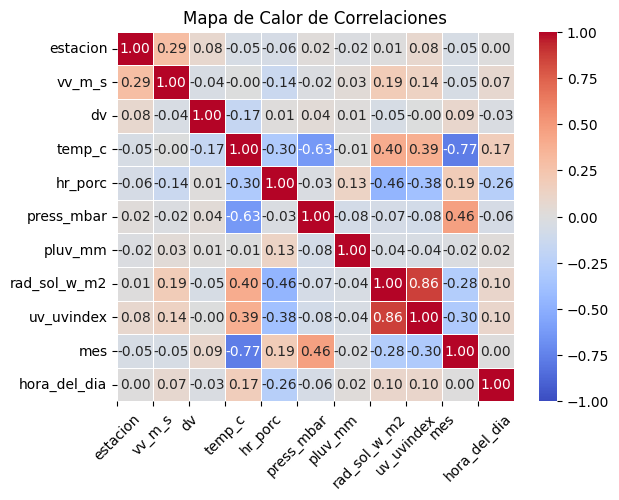

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

df_num = df_limpio.select_dtypes(include=['number'])

sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de Calor de Correlaciones')
x_labels = df_num.columns
plt.xticks(range(len(x_labels)), x_labels, rotation=45)
plt.show()

Del análisis de la matriz de correlación se desprende que la temperatura ambiental (temp_c) está fuertemente condicionada por factores estacionales y energéticos. La radiación solar ($0.40$) y el índice UV ($0.38$) operan como los principales inductores positivos del aumento térmico. Por otro lado, se destaca una marcada relación inversa con la presión atmosférica ($-0.63$) y el avance de los meses del año ($-0.77$), evidenciando los cambios estacionales del período 2012. Variables como la humedad relativa muestran un peso moderado ($-0.21$), mientras que el viento y las precipitaciones presentan una incidencia lineal directa menor sobre la temperatura general.

Tomando la fuerte relacion inversa de la temperatura con el avance de los meses del año, se visualiza un grafico de lineas.

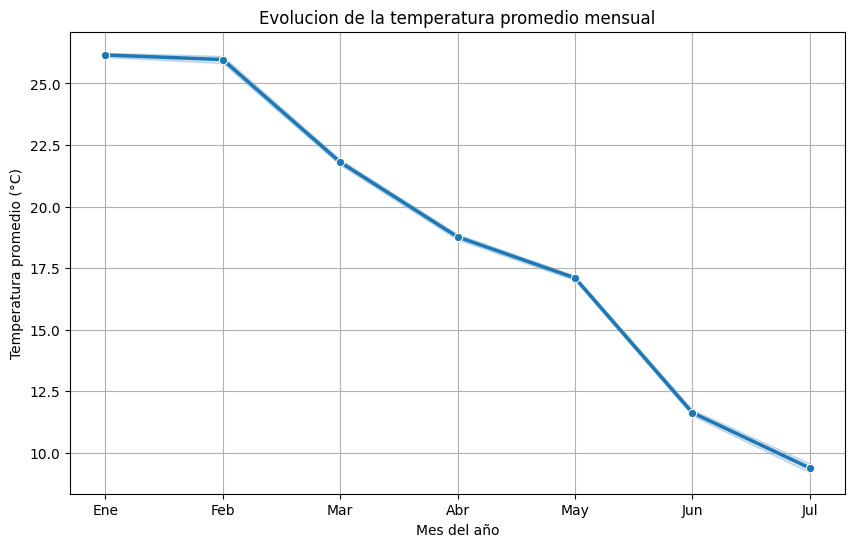

In [ ]:
plt.figure(figsize=(10,6))

sns.lineplot(data=df_limpio, x='mes', y='temp_c', estimator='mean', marker='o', linewidth=2.5)

plt.title("Evolucion de la temperatura promedio mensual")
plt.xlabel("Mes del año")
plt.ylabel("Temperatura promedio (°C)")
plt.xticks(range(1, 8), labels=['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul'])
plt.grid(True)
plt.show()

Se puede ver de manera mas clara esta correlacion, a medida que avanzan los meses, disminuye la temperatura promedio.

Tomando el analisis anterior de los registros por estacion, se visualiza como se comportan las temperaturas en cada una.

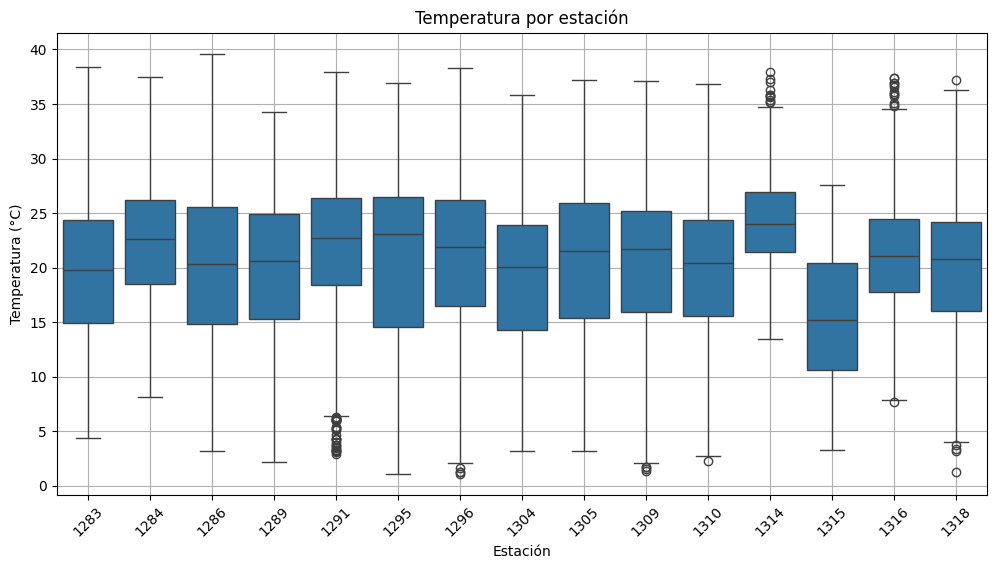

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df_limpio, x='estacion', y='temp_c')

plt.title("Temperatura por estación")
plt.xlabel("Estación")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45)
plt.grid(True)

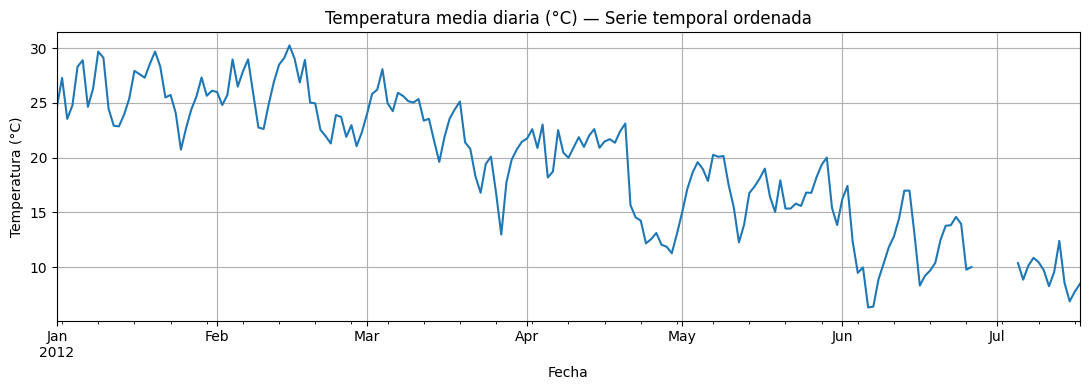

Train filas: 22976 | Rango: 2012-01-01 00:00:00 -> 2012-05-16 20:00:00
Test  filas: 5744 | Rango: 2012-05-16 20:00:00 -> 2012-07-17 13:00:00


In [ ]:
# Gráfico exploratorio directo con Pandas: temperatura media diaria
df_diario = df_limpio.set_index('timestamp')[['temp_c', 'hr_porc']].resample('D').mean()
ax = df_diario['temp_c'].plot(
    figsize=(11, 4),
    title='Temperatura media diaria (°C) — Serie temporal ordenada',
    xlabel='Fecha',
    ylabel='Temperatura (°C)',
    grid=True
)
plt.tight_layout()
plt.show()

# Creación de rezagos simples (información disponible hasta el instante anterior)
df_model = df_limpio.copy()
for col in ['temp_c', 'hr_porc', 'press_mbar', 'vv_m_s', 'rad_sol_w_m2', 'pluv_mm']:
    df_model[f'{col}_lag1'] = df_model[col].shift(1)

df_model = df_model.dropna().reset_index(drop=True)

features = [
    'estacion', 'vv_m_s', 'dv', 'hr_porc', 'press_mbar',
    'pluv_mm', 'rad_sol_w_m2', 'uv_uvindex', 'mes', 'hora_del_dia',
    'temp_c_lag1', 'hr_porc_lag1', 'press_mbar_lag1', 'rad_sol_w_m2_lag1'
]

# División cronológica 80% Train / 20% Test
split_idx = int(len(df_model) * 0.8)
train_df = df_model.iloc[:split_idx].copy()
test_df = df_model.iloc[split_idx:].copy()

print("Train filas:", len(train_df), "| Rango:", train_df['timestamp'].min(), "->", train_df['timestamp'].max())
print("Test  filas:", len(test_df),  "| Rango:", test_df['timestamp'].min(),  "->", test_df['timestamp'].max())

Visualizamos la evolución de la temperatura media diaria para observar la estacionalidad del período analizado y generamos variables rezagadas de 1 paso (`lag1`) junto con el corte cronológico **80% entrenamiento / 20% prueba** (sin mezcla aleatoria).

### Observaciones sobre la serie temporal y el particionado
* El gráfico diario refleja claramente el cambio estacional: temperaturas altas en verano (`~25–30 °C` en enero-febrero) descendiendo progresivamente hacia otoño/invierno (`~6–15 °C` en junio-julio).
* El conjunto de entrenamiento abarca **22,976 registros** (`01/01/2012` al `16/05/2012`) y el de prueba **5,744 registros** (`16/05/2012` al `17/07/2012`), garantizando una evaluación realista hacia el futuro.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    classification_report, silhouette_score
)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

# Parte 3. Aprendizaje Supervisado — Regresión (`temp_c`) y Optimización Temporal
Comparamos un modelo base de **Persistencia (`temp_c_lag1`)**, una regresión lineal regularizada (**Ridge**) y un **RandomForestRegressor** optimizado mediante `GridSearchCV` con validación cruzada temporal (`TimeSeriesSplit`) para prevenir el sobreajuste sin romper el orden cronológico.

Mejores hiperparámetros Regresión: {'max_depth': 12, 'min_samples_leaf': 20, 'n_estimators': 150}

=== RESUMEN REGRESIÓN (TEST CRONOLÓGICO) ===
                 Modelo    MAE   RMSE     R2
    Persistencia (lag1) 0.7984 1.1249 0.9297
                  Ridge 1.0054 1.2983 0.9063
RandomForest Optimizado 1.2624 1.8436 0.8111


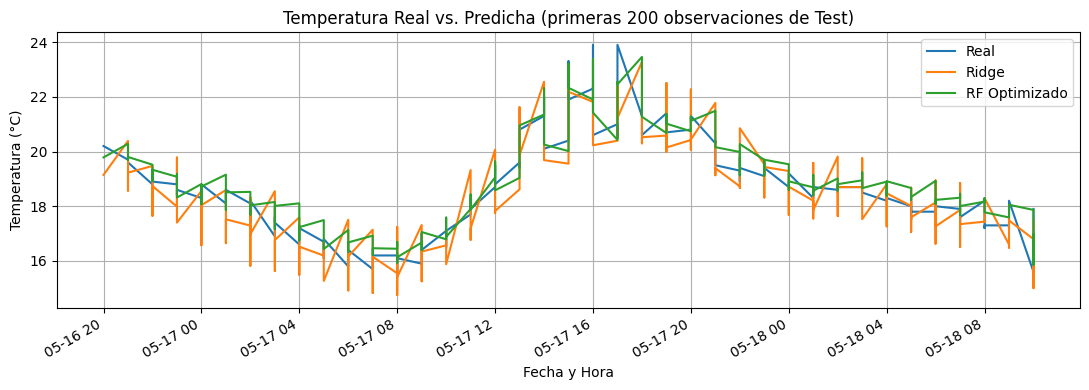

In [ ]:
X_train_r, y_train_r = train_df[features], train_df['temp_c']
X_test_r,  y_test_r  = test_df[features],  test_df['temp_c']

# 1. Baseline: Persistencia (temperatura del paso anterior)
pred_pers = test_df['temp_c_lag1']

# 2. Modelo lineal regularizado: Ridge
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
ridge.fit(X_train_r, y_train_r)
pred_ridge = ridge.predict(X_test_r)

# 3. Random Forest con optimización de hiperparámetros y TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=4)
grid_reg = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid={
        'n_estimators': [100, 150],
        'max_depth': [6, 10, 12],
        'min_samples_leaf': [10, 20]
    },
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
grid_reg.fit(X_train_r, y_train_r)
best_rf_reg = grid_reg.best_estimator_
pred_rf_opt = best_rf_reg.predict(X_test_r)

print("Mejores hiperparámetros Regresión:", grid_reg.best_params_)

# Tabla comparativa de métricas
resumen_reg = pd.DataFrame({
    'Modelo': ['Persistencia (lag1)', 'Ridge', 'RandomForest Optimizado'],
    'MAE': [
        mean_absolute_error(y_test_r, pred_pers),
        mean_absolute_error(y_test_r, pred_ridge),
        mean_absolute_error(y_test_r, pred_rf_opt)
    ],
    'RMSE': [
        root_mean_squared_error(y_test_r, pred_pers),
        root_mean_squared_error(y_test_r, pred_ridge),
        root_mean_squared_error(y_test_r, pred_rf_opt)
    ],
    'R2': [
        r2_score(y_test_r, pred_pers),
        r2_score(y_test_r, pred_ridge),
        r2_score(y_test_r, pred_rf_opt)
    ]
}).round(4)

print("\n=== RESUMEN REGRESIÓN (TEST CRONOLÓGICO) ===")
print(resumen_reg.to_string(index=False))

# Gráfico de comparación: Real vs Predicho en una ventana de 200 horas de Test
df_comp_reg = pd.DataFrame({
    'Real': y_test_r.iloc[:200].values,
    'Ridge': pred_ridge[:200],
    'RF Optimizado': pred_rf_opt[:200]
}, index=test_df['timestamp'].iloc[:200])

df_comp_reg.plot(
    figsize=(11, 4),
    title='Temperatura Real vs. Predicha (primeras 200 observaciones de Test)',
    xlabel='Fecha y Hora',
    ylabel='Temperatura (°C)',
    grid=True
)
plt.tight_layout()
plt.show()

### Análisis de Resultados — Regresión
* **Persistencia (`lag1`)** obtiene las mejores métricas (**MAE = 0.7984 °C**, **RMSE = 1.1249 °C**, **R² = 0.9297**), seguido de cerca por **Ridge** (**MAE = 1.0054 °C**, **RMSE = 1.2983 °C**, **R² = 0.9063**).
* La optimización con `GridSearchCV` + `TimeSeriesSplit` seleccionó `{'max_depth': 12, 'min_samples_leaf': 20, 'n_estimators': 150}`, mejorando el desempeño del **Random Forest** en prueba (**MAE = 1.2624 °C**, **RMSE = 1.8436 °C**, **R² = 0.8111**) frente a configuraciones menos regularizadas.
* **Interpretación:** En series meteorológicas continuas existe una fuerte inercia térmica de corto plazo; además, los modelos lineales extrapolan mejor que los árboles de decisión cuando el conjunto de prueba entra en un régimen más frío que el visto en entrenamiento.

## Aprendizaje Supervisado — Clasificación de Nivel Térmico
Discretizamos la temperatura en tres categorías (`Baja`, `Media`, `Alta`) calculando los umbrales de terciles **únicamente sobre el conjunto de entrenamiento** para evitar fuga de información. Luego optimizamos un `RandomForestClassifier` mediante `GridSearchCV` con `TimeSeriesSplit`.

Distribución de clases en TEST:
temp_c
Baja     5617
Media     127
Alta        0
Name: count, dtype: int64

Mejores hiperparámetros Clasificación: {'max_depth': 12, 'min_samples_leaf': 10, 'n_estimators': 150}

Matriz de confusión (Test):
Predicho  Baja  Media
Real                 
Baja      5594     23
Media       26    101

Reporte de clasificación:
              precision    recall  f1-score   support

        Baja      0.995     0.996     0.996      5617
       Media      0.815     0.795     0.805       127

    accuracy                          0.991      5744
   macro avg      0.905     0.896     0.900      5744
weighted avg      0.991     0.991     0.991      5744



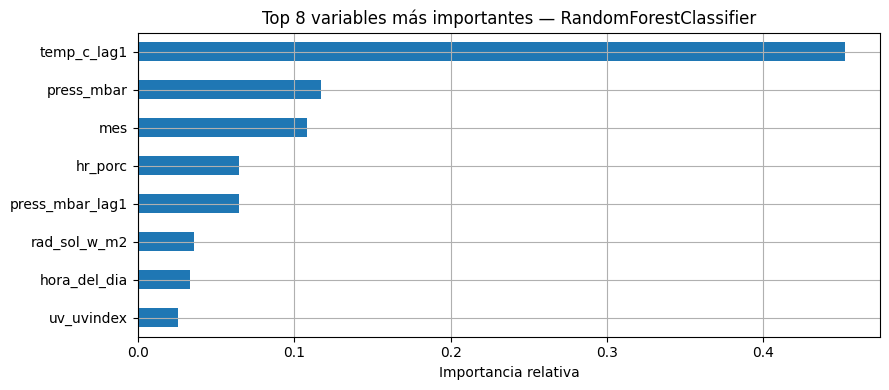

In [ ]:
# Definición de terciles exclusivamente en Train
tercil_bins = pd.qcut(train_df['temp_c'], q=3, retbins=True)[1]
tercil_bins[0] = -np.inf
tercil_bins[-1] = np.inf

etiquetas_temp = ['Baja', 'Media', 'Alta']
y_train_c = pd.cut(train_df['temp_c'], bins=tercil_bins, labels=etiquetas_temp)
y_test_c  = pd.cut(test_df['temp_c'],  bins=tercil_bins, labels=etiquetas_temp)

print("Distribución de clases en TEST:")
print(y_test_c.value_counts())

# Optimización temporal con GridSearchCV
grid_clf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid={
        'n_estimators': [100, 150],
        'max_depth': [6, 10, 12],
        'min_samples_leaf': [10, 20]
    },
    cv=tscv,
    scoring='f1_macro',
    n_jobs=-1
)
grid_clf.fit(X_train_r, y_train_c)
best_rf_clf = grid_clf.best_estimator_
pred_best_clf = best_rf_clf.predict(X_test_r)

print("\nMejores hiperparámetros Clasificación:", grid_clf.best_params_)

matriz_conf = pd.crosstab(
    y_test_c,
    pd.Series(pred_best_clf, index=y_test_c.index),
    rownames=['Real'],
    colnames=['Predicho']
)
print("\nMatriz de confusión (Test):")
print(matriz_conf)

print("\nReporte de clasificación:")
print(classification_report(y_test_c, pred_best_clf, digits=3))

# Gráfico de importancia de variables del clasificador (con Pandas)
importancias = pd.Series(best_rf_clf.feature_importances_, index=features).sort_values(ascending=True)
importancias.tail(8).plot(
    kind='barh',
    figsize=(9, 4),
    title='Top 8 variables más importantes — RandomForestClassifier',
    xlabel='Importancia relativa',
    grid=True
)
plt.tight_layout()
plt.show()

### Análisis de Resultados — Clasificación
* Debido al desplazamiento estacional hacia el invierno en el tramo de prueba, **5,617** registros pertenecen a la clase `Baja`, **127** a `Media` y **0** a `Alta`.
* El modelo optimizado (`{'max_depth': 12, 'min_samples_leaf': 10, 'n_estimators': 150}`) alcanza un **Accuracy global de 0.991** y un **Macro F1-score de 0.900** (**F1 = 0.996** en `Baja` y **F1 = 0.805** en `Media`), demostrando alta capacidad para detectar transiciones térmicas incluso bajo desbalance estacional.

# Parte 4. Aprendizaje No Supervisado — Clustering, Silhouette y PCA
Estandarizamos las variables meteorológicas continuas (`temp_c`, `hr_porc`, `press_mbar`, `vv_m_s`, `rad_sol_w_m2`, `uv_uvindex`) para descubrir regímenes atmosféricos sin etiquetas:
1. Evaluamos **K-Means** para $k \in \{2, 3, 4, 5, 6\}$ mediante **Inercia** (método del codo) y **Silhouette Score**.
2. Reducimos dimensionalidad con **PCA (2 componentes)** para visualizar la separación de grupos.
3. Comparamos el desempeño de **K-Means** contra **Clustering Jerárquico Agglomerative (enlace Ward)**.

 k      Inercia  Silhouette
 2 41433.957010    0.395987
 3 32812.622719    0.251890
 4 28578.228214    0.261688
 5 25129.162056    0.231876
 6 23214.401008    0.211318

Mejor k seleccionado por Silhouette: 2 (Silhouette = 0.3960)

=== COMPARACIÓN DE ALGORITMOS (n=10000, k=2) ===
K-Means (centroide)          -> Silhouette: 0.3929 | Tamaños: [8053 1947]
Agglomerative (Ward linkage) -> Silhouette: 0.3559 | Tamaños: [8148 1852]

Promedios originales por cluster (K-Means):
                temp_c  hr_porc  press_mbar  vv_m_s  rad_sol_w_m2  uv_uvindex
cluster_kmeans                                                               
0                19.17    69.48     1011.86    0.56         37.15        0.44
1                26.29    52.74     1010.22    1.03        570.74        7.11

Varianza explicada PCA: PC1=42.63%, PC2=23.23% | Total=65.86%


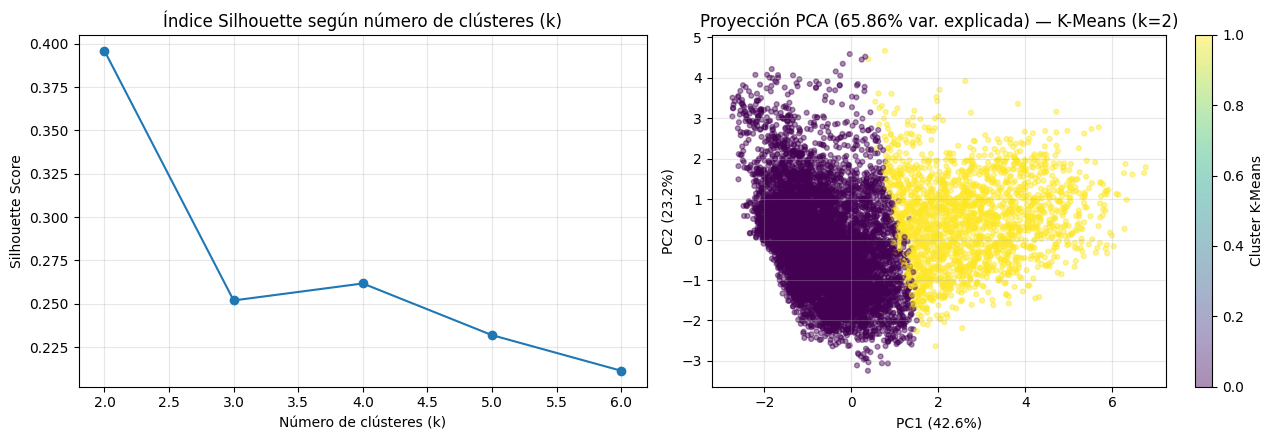

In [ ]:
cols_cluster = ['temp_c', 'hr_porc', 'press_mbar', 'vv_m_s', 'rad_sol_w_m2', 'uv_uvindex']
df_clust_full = df_limpio[cols_cluster].dropna().copy()

scaler_c = StandardScaler()
X_clust_scaled = scaler_c.fit_transform(df_clust_full)

# Muestra reproducible de 10,000 registros para evaluación eficiente de Silhouette y jerárquico
rng = np.random.default_rng(42)
idx_sample = rng.choice(len(X_clust_scaled), size=min(10000, len(X_clust_scaled)), replace=False)
X_sample = X_clust_scaled[idx_sample]

resultados_k = []
mejor_k = None
mejor_sil = -1.0

for k in [2, 3, 4, 5, 6]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_s = km.fit_predict(X_sample)
    sil = silhouette_score(X_sample, labels_s)
    resultados_k.append({'k': k, 'Inercia': km.inertia_, 'Silhouette': sil})
    if sil > mejor_sil:
        mejor_sil = sil
        mejor_k = k

df_k_eval = pd.DataFrame(resultados_k)
print(df_k_eval.to_string(index=False))
print(f"\nMejor k seleccionado por Silhouette: {mejor_k} (Silhouette = {mejor_sil:.4f})")

# Ajuste final de K-Means sobre todo el dataset limpio
kmeans_final = KMeans(n_clusters=mejor_k, random_state=42, n_init=10)
clusters_km = kmeans_final.fit_predict(X_clust_scaled)
df_clust_full['cluster_kmeans'] = clusters_km

# Comparación con Clustering Jerárquico (Ward) sobre la misma muestra
agg = AgglomerativeClustering(n_clusters=mejor_k, linkage='ward')
labels_agg_s = agg.fit_predict(X_sample)
sil_agg = silhouette_score(X_sample, labels_agg_s)

labels_km_s = kmeans_final.predict(X_sample)
sil_km_s = silhouette_score(X_sample, labels_km_s)

print(f"\n=== COMPARACIÓN DE ALGORITMOS (n={len(X_sample)}, k={mejor_k}) ===")
print(f"K-Means (centroide)          -> Silhouette: {sil_km_s:.4f} | Tamaños: {np.bincount(labels_km_s)}")
print(f"Agglomerative (Ward linkage) -> Silhouette: {sil_agg:.4f} | Tamaños: {np.bincount(labels_agg_s)}")

print("\nPromedios originales por cluster (K-Means):")
print(df_clust_full.groupby('cluster_kmeans')[cols_cluster].mean().round(2))

# PCA para visualización 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_clust_scaled)
var_exp = pca.explained_variance_ratio_
print(f"\nVarianza explicada PCA: PC1={var_exp[0]*100:.2f}%, PC2={var_exp[1]*100:.2f}% | Total={var_exp.sum()*100:.2f}%")

# Panel visual: Curva Silhouette vs k y Proyección PCA
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(df_k_eval['k'], df_k_eval['Silhouette'], marker='o')
axes[0].set_title('Índice Silhouette según número de clústeres (k)')
axes[0].set_xlabel('Número de clústeres (k)')
axes[0].set_ylabel('Silhouette Score')
axes[0].grid(True, alpha=0.3)

sc = axes[1].scatter(
    X_pca[idx_sample, 0],
    X_pca[idx_sample, 1],
    c=clusters_km[idx_sample],
    alpha=0.45,
    s=12
)
axes[1].set_title(f'Proyección PCA ({var_exp.sum()*100:.2f}% var. explicada) — K-Means (k={mejor_k})')
axes[1].set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)')
plt.colorbar(sc, ax=axes[1], label='Cluster K-Means')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Conclusiones Generales del Proyecto

1. **Integridad de datos y prevención de *data leakage*:**
   A partir de **29,559 registros** meteorológicos (`2012-01-01` a `2012-07-17`), la validación de rangos físicos permitió depurar errores de sensor en temperatura (`600` lecturas en `1802.6 °C`) y en humedad relativa (`238` registros fuera de `[0%, 100%]`), conservando **28,721 registros** válidos. Construir un `timestamp` unificado y respetar el orden cronológico en todas las particiones (`train`/`test` y `TimeSeriesSplit`) evitó filtraciones temporales y garantizó métricas realistas.

2. **Aprendizaje supervisado — Regresión (`temp_c`):**
   Bajo evaluación cronológica, el modelo base de **Persistencia (`temp_c_lag1`)** alcanzó el menor error (**MAE = 0.7984 °C**, **RMSE = 1.1249 °C**, **R² = 0.9297**), seguido por **Ridge** (**MAE = 1.0054 °C**, **RMSE = 1.2983 °C**, **R² = 0.9063**). La optimización mediante `GridSearchCV` con `TimeSeriesSplit` (`max_depth=12`, `min_samples_leaf=20`, `n_estimators=150`) mejoró la generalización del **Random Forest** (**MAE = 1.2624 °C**, **RMSE = 1.8436 °C**, **R² = 0.8111**), confirmando tanto la fuerte inercia térmica horaria como el límite de extrapolación de los árboles frente a cambios estacionales.

3. **Aprendizaje supervisado — Clasificación de nivel térmico:**
   Definiendo los terciles exclusivamente sobre el entrenamiento cálido y evaluando sobre el tramo frío de prueba (`5,617` casos `Baja`, `127` `Media` y `0` `Alta`), el **RandomForestClassifier** optimizado (`max_depth=12`, `min_samples_leaf=10`, `n_estimators=150`) obtuvo un **Accuracy de 0.991** y un **Macro F1-score de 0.900** (**F1 = 0.996** en `Baja` y **F1 = 0.805** en `Media`).

4. **Aprendizaje no supervisado — Clustering y PCA:**
   La evaluación de **Silhouette Score** determinó **`k = 2`** como la partición óptima, respaldada por una proyección **PCA** que captura el **65.86%** de la varianza total en dos componentes. **K-Means** (**Silhouette = 0.3929**) superó al **Clustering Jerárquico Agglomerative con enlace Ward** (**Silhouette = 0.3559**), identificando dos estados meteorológicos físicamente coherentes:
   * **Clúster 0 (~80.5%):** régimen nocturno o de baja irradiancia (`rad_sol_w_m2 ≈ 37.2 W/m²`, `uv_uvindex ≈ 0.44`), humedad elevada (`69.5%`) y temperatura media más baja (`19.2 °C`).
   * **Clúster 1 (~19.5%):** régimen diurno soleado de alta radiación (`rad_sol_w_m2 ≈ 570.7 W/m²`, `uv_uvindex ≈ 7.11`), menor humedad (`52.7%`) y mayor temperatura media (`26.3 °C`).